In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
crashes_df = pd.read_csv("../data/crashes.csv", nrows=5)

print("Crash dataset loaded successfully!")
display(crashes_df)

Crash dataset loaded successfully!


,CRASH DATE,CRASH TIME,BOROUGH,ZIP CODE,LATITUDE,LONGITUDE,LOCATION,ON STREET NAME,CROSS STREET NAME,OFF STREET NAME,...,CONTRIBUTING FACTOR VEHICLE 2,CONTRIBUTING FACTOR VEHICLE 3,CONTRIBUTING FACTOR VEHICLE 4,CONTRIBUTING FACTOR VEHICLE 5,COLLISION_ID,VEHICLE TYPE CODE 1,VEHICLE TYPE CODE 2,VEHICLE TYPE CODE 3,VEHICLE TYPE CODE 4,VEHICLE TYPE CODE 5
0,10/26/2026,09:50,QUEENS,11354.0,40.758366,-73.831535,"(40.758366, -73.831535)",PRINCE ST,NaN,40 RD,...,NaN,NaN,NaN,NaN,519c24301482cf3ce3d5240026e81c22,NaN,NaN,NaN,NaN,NaN
1,10/26/2026,17:27,MANHATTAN,10001.0,40.747463,-73.989235,"(40.747463, -73.989235)",NaN,864 AVENUE OF THE AMERICAS,NaN,...,NaN,NaN,NaN,NaN,acbd04e071dcaa2578958711f8e4902f,NaN,NaN,NaN,NaN,NaN
2,10/26/2026,08:02,STATEN ISLAND,10307.0,40.509937,-74.243480,"(40.509937, -74.24348)",NaN,7396 AMBOY RD,NaN,...,NaN,NaN,NaN,NaN,8317d3a295013151d344f7f91e1bb6d8,NaN,NaN,NaN,NaN,NaN
3,10/26/2026,16:25,BROOKLYN,NaN,40.669544,-73.917140,"(40.669544, -73.91714)",SARATOGA AVE,NaN,E NEW YORK AVE,...,NaN,NaN,NaN,NaN,58cc840cb9bc2ea1ae4ba15b0c0f9e66,NaN,NaN,NaN,NaN,NaN
4,10/26/2026,19:20,BROOKLYN,11213.0,40.672230,-73.944710,"(40.67223, -73.94471)",BROOKLYN AVE,NaN,STERLING PL,...,Does Not Apply,NaN,NaN,NaN,d532916f44a6341b4741608673142258,Station Wagon/Sport Utility Vehicle,4 dr sedan,NaN,NaN,NaN


In [3]:
print("Columns:")
print(crashes_df.columns.tolist())

print("\nNumber of columns:", len(crashes_df.columns))

Columns:
['CRASH DATE', 'CRASH TIME', 'BOROUGH', 'ZIP CODE', 'LATITUDE', 'LONGITUDE', 'LOCATION', 'ON STREET NAME', 'CROSS STREET NAME', 'OFF STREET NAME', 'NUMBER OF PERSONS INJURED', 'NUMBER OF PERSONS KILLED', 'NUMBER OF PEDESTRIANS INJURED', 'NUMBER OF PEDESTRIANS KILLED', 'NUMBER OF CYCLIST INJURED', 'NUMBER OF CYCLIST KILLED', 'NUMBER OF MOTORIST INJURED', 'NUMBER OF MOTORIST KILLED', 'CONTRIBUTING FACTOR VEHICLE 1', 'CONTRIBUTING FACTOR VEHICLE 2', 'CONTRIBUTING FACTOR VEHICLE 3', 'CONTRIBUTING FACTOR VEHICLE 4', 'CONTRIBUTING FACTOR VEHICLE 5', 'COLLISION_ID', 'VEHICLE TYPE CODE 1', 'VEHICLE TYPE CODE 2', 'VEHICLE TYPE CODE 3', 'VEHICLE TYPE CODE 4', 'VEHICLE TYPE CODE 5']

Number of columns: 29


RQ3: Which NYC borough has the highest number of reported motor vehicle collisions?

Visualization: Bar chart comparing crashes across boroughs.

RQ4: At what time of day do motor vehicle collisions occur most frequently?

Visualization: Bar chart showing crash frequency across the 24 hours of the day.

These are proposed questions; confirm that your team hasn't already assigned different Q3 and Q4 questions.

In [4]:
crash_columns = [
    "CRASH DATE",
    "CRASH TIME",
    "BOROUGH",
    "NUMBER OF PERSONS INJURED",
    "NUMBER OF PERSONS KILLED",
    "COLLISION_ID"
]

crashes_df = pd.read_csv(
    "../data/crashes.csv",
    usecols=crash_columns,
    low_memory=False
)

print("Complete crash dataset loaded!")
print("Dataset shape:", crashes_df.shape)

display(crashes_df.head())

Complete crash dataset loaded!
Dataset shape: (2301383, 6)


,CRASH DATE,CRASH TIME,BOROUGH,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED,COLLISION_ID
0,10/26/2026,09:50,QUEENS,1.0,0.0,519c24301482cf3ce3d5240026e81c22
1,10/26/2026,17:27,MANHATTAN,1.0,0.0,acbd04e071dcaa2578958711f8e4902f
2,10/26/2026,08:02,STATEN ISLAND,1.0,0.0,8317d3a295013151d344f7f91e1bb6d8
3,10/26/2026,16:25,BROOKLYN,0.0,0.0,58cc840cb9bc2ea1ae4ba15b0c0f9e66
4,10/26/2026,19:20,BROOKLYN,1.0,0.0,d532916f44a6341b4741608673142258


In [5]:
print("Dataset dimensions:", crashes_df.shape)

print("\nMissing values:")
print(crashes_df.isnull().sum())

print("\nDuplicate collision IDs:")
print(crashes_df["COLLISION_ID"].duplicated().sum())

print("\nData types:")
print(crashes_df.dtypes)

Dataset dimensions: (2301383, 6)

Missing values:
CRASH DATE                        0
CRASH TIME                        0
BOROUGH                      674806
NUMBER OF PERSONS INJURED        18
NUMBER OF PERSONS KILLED         31
COLLISION_ID                      0
dtype: int64

Duplicate collision IDs:
0

Data types:
CRASH DATE                       str
CRASH TIME                       str
BOROUGH                          str
NUMBER OF PERSONS INJURED    float64
NUMBER OF PERSONS KILLED     float64
COLLISION_ID                     str
dtype: object


In [6]:
# Check borough categories
print("Borough values:")
print(crashes_df["BOROUGH"].value_counts(dropna=False))

# Check date range
print("\nDate range:")
print("Earliest:", crashes_df["CRASH DATE"].min())
print("Latest:", crashes_df["CRASH DATE"].max())

# Check time formats
print("\nFirst 20 crash times:")
print(crashes_df["CRASH TIME"].head(20).tolist())

# Check invalid dates
dates = pd.to_datetime(
    crashes_df["CRASH DATE"],
    format="%m/%d/%Y",
    errors="coerce"
)

print("\nInvalid dates:", dates.isna().sum())

Borough values:
BOROUGH
NaN              674806
BROOKLYN         521443
QUEENS           437651
MANHATTAN        356811
BRONX            242873
STATEN ISLAND     67799
Name: count, dtype: int64

Date range:
Earliest: 01/01/2013
Latest: 12/31/2025

First 20 crash times:
['09:50', '17:27', '08:02', '16:25', '19:20', '14:00', '02:39', '03:42', '15:20', '01:15', '13:00', '18:19', '06:27', '10:50', '17:01', '14:18', '14:23', '00:04', '09:55', '22:00']

Invalid dates: 0


In [7]:
# Create a separate copy
crashes_clean = crashes_df.copy()

# Convert crash dates into proper datetime values
crashes_clean["CRASH DATE"] = pd.to_datetime(
    crashes_clean["CRASH DATE"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Clean and convert crash times
time_parsed = pd.to_datetime(
    crashes_clean["CRASH TIME"].astype("string").str.strip(),
    format="%H:%M",
    errors="coerce"
)

# Extract the hour for our time analysis
crashes_clean["CRASH HOUR"] = time_parsed.dt.hour

# Standardize borough names
crashes_clean["BOROUGH"] = (
    crashes_clean["BOROUGH"].str.strip().str.upper()
)

# Display results
print("Earliest crash date:", crashes_clean["CRASH DATE"].min())
print("Latest crash date:", crashes_clean["CRASH DATE"].max())

print("Invalid dates:", crashes_clean["CRASH DATE"].isna().sum())
print("Invalid times:", time_parsed.isna().sum())

print("\nCleaned dataset:")
display(crashes_clean.head())


Earliest crash date: 2012-07-01 00:00:00
Latest crash date: 2026-10-26 00:00:00
Invalid dates: 0
Invalid times: 0

Cleaned dataset:


,CRASH DATE,CRASH TIME,BOROUGH,NUMBER OF PERSONS INJURED,NUMBER OF PERSONS KILLED,COLLISION_ID,CRASH HOUR
0,2026-10-26,09:50,QUEENS,1.0,0.0,519c24301482cf3ce3d5240026e81c22,9
1,2026-10-26,17:27,MANHATTAN,1.0,0.0,acbd04e071dcaa2578958711f8e4902f,17
2,2026-10-26,08:02,STATEN ISLAND,1.0,0.0,8317d3a295013151d344f7f91e1bb6d8,8
3,2026-10-26,16:25,BROOKLYN,0.0,0.0,58cc840cb9bc2ea1ae4ba15b0c0f9e66,16
4,2026-10-26,19:20,BROOKLYN,1.0,0.0,d532916f44a6341b4741608673142258,19


In [8]:
print("Total crash records:", len(crashes_clean))

print("Invalid dates:",
      crashes_clean["CRASH DATE"].isna().sum())

print("Invalid crash hours:",
      crashes_clean["CRASH HOUR"].isna().sum())

print("Earliest crash date:",
      crashes_clean["CRASH DATE"].min())

print("Latest crash date:",
      crashes_clean["CRASH DATE"].max())

print("\nMissing values:")
print(crashes_clean.isnull().sum())

Total crash records: 2301383
Invalid dates: 0
Invalid crash hours: 0
Earliest crash date: 2012-07-01 00:00:00
Latest crash date: 2026-10-26 00:00:00

Missing values:
CRASH DATE                        0
CRASH TIME                        0
BOROUGH                      674806
NUMBER OF PERSONS INJURED        18
NUMBER OF PERSONS KILLED         31
COLLISION_ID                      0
CRASH HOUR                        0
dtype: int64


In [9]:
borough_crashes = (
    crashes_clean
    .dropna(subset=["BOROUGH"])
    .groupby("BOROUGH")
    .size()
    .sort_values(ascending=False)
    .to_frame(name="Number of Crashes")
)

display(borough_crashes)

,Number of Crashes
BOROUGH,
BROOKLYN,521443
QUEENS,437651
MANHATTAN,356811
BRONX,242873
STATEN ISLAND,67799


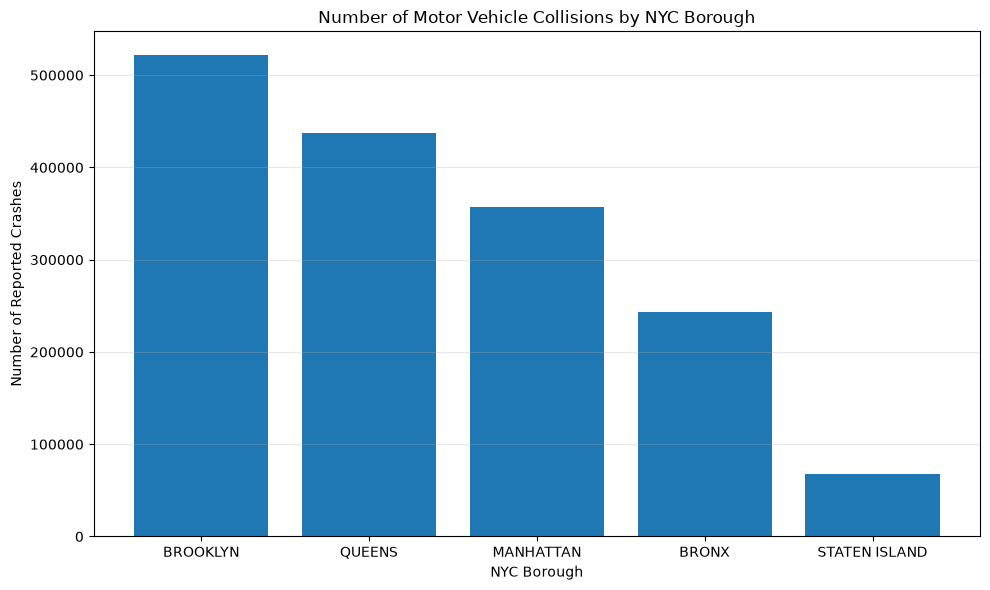

In [10]:
plt.figure(figsize=(10, 6))

plt.bar(
    borough_crashes.index,
    borough_crashes["Number of Crashes"]
)

plt.title("Number of Motor Vehicle Collisions by NYC Borough")
plt.xlabel("NYC Borough")
plt.ylabel("Number of Reported Crashes")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
hourly_crashes = (
    crashes_clean
    .groupby("CRASH HOUR")
    .size()
    .reindex(range(24), fill_value=0)
    .to_frame(name="Number of Crashes")
)

display(hourly_crashes)

,Number of Crashes
CRASH HOUR,
0,77254
1,41285
2,31921
3,28132
4,31957
5,34534
6,52400
7,71718
8,125762


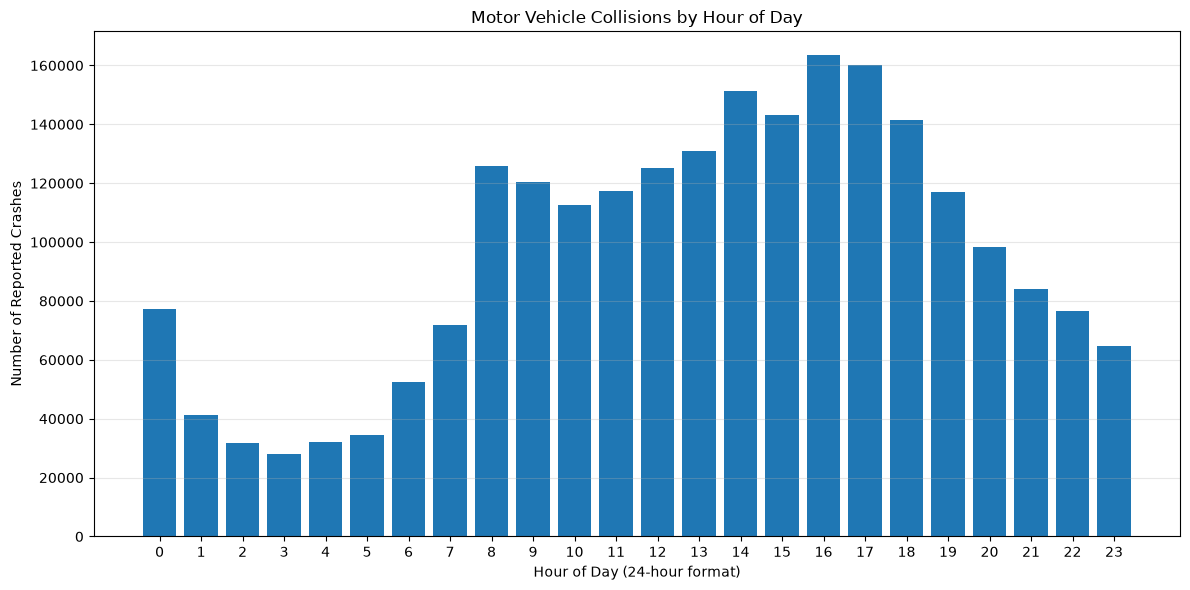

In [12]:
plt.figure(figsize=(12, 6))

plt.bar(
    hourly_crashes.index,
    hourly_crashes["Number of Crashes"]
)

plt.title("Motor Vehicle Collisions by Hour of Day")
plt.xlabel("Hour of Day (24-hour format)")
plt.ylabel("Number of Reported Crashes")

plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [1]:
import pandas as pd
import numpy as np

# 1. Load original dataset
crashes = pd.read_csv("../data/crashes.csv")

# If your notebook is in the notebook folder,
# the path above should work.

# 2. Convert columns to appropriate types
crashes["CRASH DATE"] = pd.to_datetime(
    crashes["CRASH DATE"],
    errors="coerce"
)

crashes["CRASH TIME"] = pd.to_datetime(
    crashes["CRASH TIME"],
    format="%H:%M",
    errors="coerce"
).dt.hour

numeric_columns = [
    "NUMBER OF PERSONS INJURED",
    "NUMBER OF PERSONS KILLED",
    "NUMBER OF PEDESTRIANS INJURED",
    "NUMBER OF PEDESTRIANS KILLED",
    "NUMBER OF CYCLIST INJURED",
    "NUMBER OF CYCLIST KILLED",
    "NUMBER OF MOTORIST INJURED",
    "NUMBER OF MOTORIST KILLED"
]

for col in numeric_columns:
    crashes[col] = pd.to_numeric(
        crashes[col], errors="coerce"
    )

# 3. Standardize borough names
crashes["BOROUGH"] = (
    crashes["BOROUGH"]
    .str.strip()
    .str.upper()
)

# 4. Standardize ZIP codes
crashes["ZIP CODE"] = (
    crashes["ZIP CODE"]
    .astype("string")
    .str.replace(r"\.0$", "", regex=True)
    .str.strip()
)

# 5. Keep missing geographical values
# We will not invent missing boroughs or ZIP codes.

# 6. Remove records without a valid crash date
crashes = crashes.dropna(subset=["CRASH DATE"])

# 7. Check duplicate collision IDs
crashes = crashes.drop_duplicates(
    subset=["COLLISION_ID"]
)

# 8. Save cleaned dataset
crashes.to_csv("../data/crashes_clean.csv", index=False)

# 9. Display cleaning results
print("CLEANING COMPLETED")
print("Shape:", crashes.shape)
print("\nMissing values:")
print(crashes.isnull().sum())

print("\nBorough distribution:")
print(crashes["BOROUGH"].value_counts(dropna=False))

print("\nSaved as crashes_clean.csv")

CLEANING COMPLETED
Shape: (2303048, 29)

Missing values:
CRASH DATE                             0
CRASH TIME                             0
BOROUGH                           674848
ZIP CODE                          699891
LATITUDE                          240749
LONGITUDE                         240749
LOCATION                          240749
ON STREET NAME                    510086
CROSS STREET NAME                1885381
OFF STREET NAME                   886077
NUMBER OF PERSONS INJURED             18
NUMBER OF PERSONS KILLED              31
NUMBER OF PEDESTRIANS INJURED          0
NUMBER OF PEDESTRIANS KILLED           0
NUMBER OF CYCLIST INJURED              0
NUMBER OF CYCLIST KILLED               0
NUMBER OF MOTORIST INJURED             0
NUMBER OF MOTORIST KILLED              0
CONTRIBUTING FACTOR VEHICLE 1       8227
CONTRIBUTING FACTOR VEHICLE 2     373862
CONTRIBUTING FACTOR VEHICLE 3    2135816
CONTRIBUTING FACTOR VEHICLE 4    2264690
CONTRIBUTING FACTOR VEHICLE 5    2292531


## Research Question 4

At what time of day do motor vehicle collisions occur most frequently in NYC?

### Findings

The highest number of collisions occurred between 4:00 PM and 4:59 PM, with 163,416 recorded crashes.

The 5:00 PM hour followed with 160,191 crashes.

The lowest number occurred at 3:00 AM, with 28,132 crashes.

This suggests that reported collisions were concentrated more heavily during afternoon and evening hours.

### Conclusion

The 4:00 PM hour had the highest recorded collision count in the dataset.